# Laboratorio 4 — Análisis exploratorio de datos

**Archivo:** `lab4_IC2025.ipynb`

**Integrantes del grupo:**

* Eyner Lopez Aleman
* Neysa Alfaro
* Osvaldo Zúñiga Pérez
* José Alejandro Lopez Quesada

### Datos utilizados

El análisis usa `InvacomDW`, el DW del proyecto del curso, con la autorización del profesor para trabajar con esta fuente. La consulta [sql/dataset_hogares.sql](sql/dataset_hogares.sql) reúne los datos de 2.500 hogares, con una fila por hogar:

* `DimHogar` aporta la información demográfica: edad, ingresos, estado civil, vivienda, composición del hogar, tamaño y número de hijos.
* `FactVenta`, `DimPeriodo` y `DimProducto` permiten resumir las compras de un periodo de 711 días, casi dos años.
* `coupon_redempt` aporta los canjes de cupones registrados para cada hogar.

El script [sql/exportar_csv.ps1](sql/exportar_csv.ps1) consulta el DW y guarda `data/hogares_invacom.csv`. Ese archivo se publica en el repositorio y el notebook lo lee desde GitHub para hacer el análisis en Python.

Repositorio: <https://github.com/Eyner1/Laboratorio_4_Mineria_de_Datos_ISW_911_EDA_dataset_InvacomDW>

## 1. Librerías

El trabajo se realiza en Python. `pandas` y `numpy` se usan para revisar y transformar los datos; `matplotlib`, `seaborn` y `missingno`, para los gráficos; y `scikit-learn`, para la estandarización. Al final se propone un modelo a partir de los resultados del EDA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

# Etiquetas de presentación: se usan al dibujar, sin cambiar las columnas del análisis.
ETIQUETAS_GRAFICOS = {}
for original, nombre_es, etiqueta in [
    ("household_key", "id_hogar", "Identificador del hogar"),
    ("age_desc", "rango_edad", "Rango de edad"),
    ("marital_status_code", "estado_civil", "Estado civil"),
    ("income_desc", "rango_ingreso", "Rango de ingresos"),
    ("homeowner_desc", "tipo_vivienda", "Tipo de vivienda"),
    ("hh_comp_desc", "composicion_hogar", "Composición del hogar"),
    ("household_size_desc", "tamano_hogar", "Tamaño del hogar"),
    ("kid_category_desc", "cantidad_hijos", "Número de hijos"),
    ("total_sales", "total_ventas", "Total de ventas"),
    ("num_baskets", "cantidad_compras", "Número de compras"),
    ("avg_basket_value", "ticket_promedio", "Compra promedio"),
    ("total_quantity", "cantidad_articulos", "Cantidad registrada"),
    ("distinct_products", "productos_distintos", "Productos distintos"),
    ("distinct_stores", "tiendas_distintas", "Tiendas distintas"),
    ("active_weeks", "semanas_activas", "Semanas con compras"),
    ("first_day", "primer_dia_compra", "Primer día de compra"),
    ("last_day", "ultimo_dia_compra", "Último día de compra"),
    ("total_retail_disc", "descuento_tienda", "Descuento en tienda"),
    ("total_coupon_disc", "descuento_cupon", "Descuento con cupón"),
    ("coupons_redeemed", "cupones_canjeados", "Cupones canjeados"),
    ("top_department", "departamento_principal", "Departamento principal"),
]:
    ETIQUETAS_GRAFICOS[original] = etiqueta
    ETIQUETAS_GRAFICOS[nombre_es] = etiqueta
ETIQUETAS_GRAFICOS["tiene_demografia"] = "Con datos demográficos"

ETIQUETAS_CATEGORIAS = {
    "GROCERY": "Abarrotes",
    "DRUG GM": "Farmacia y artículos generales",
    "KIOSK-GAS": "Combustible",
    "MEAT": "Carnes",
    "MISC SALES TRAN": "Transacciones varias",
    "PRODUCE": "Frutas y verduras",
    "NUTRITION": "Nutrición",
    "PASTRY": "Repostería",
    "DELI": "Comidas preparadas",
    "SPIRITS": "Licores",
    "COSMETICS": "Cosméticos",
    "MEAT-PCKGD": "Carnes empacadas",
    "SALAD BAR": "Barra de ensaladas",
    "OTROS": "Otros",
    "Homeowner": "Propia",
    "Probable Owner": "Probablemente propia",
    "Probable Renter": "Probablemente alquilada",
    "Renter": "Alquilada",
    "2 Adults Kids": "Dos adultos con hijos",
    "2 Adults No Kids": "Dos adultos sin hijos",
    "1 Adult Kids": "Un adulto con hijos",
    "Single Female": "Mujer sola",
    "Single Male": "Hombre solo",
    "Unknown": "Desconocido",
    "Desconocido": "Desconocido",
    "Soltero": "Soltero",
}


def etiqueta_grafico(nombre):
    """Devuelve un nombre legible en español para variables y categorías."""
    if nombre in ETIQUETAS_GRAFICOS:
        return ETIQUETAS_GRAFICOS[nombre]
    for columna, prefijo in {
        "estado_civil": "Estado civil",
        "tipo_vivienda": "Vivienda",
        "composicion_hogar": "Hogar",
        "departamento_principal": "Departamento",
    }.items():
        if nombre.startswith(columna + "_"):
            categoria = nombre[len(columna) + 1:]
            traduccion = ETIQUETAS_CATEGORIAS.get(categoria, categoria)
            return f"{prefijo}: {traduccion.lower()}"
    return nombre.replace("_", " ")


## 2. Lectura de los datos desde GitHub

La lectura usa el enlace Raw del CSV, que entrega el archivo directamente. `encoding="utf-8-sig"` permite manejar el BOM que trae el archivo al inicio.

In [2]:
URL_DATASET = (
    "https://raw.githubusercontent.com/Eyner1/"
    "Laboratorio_4_Mineria_de_Datos_ISW_911_EDA_dataset_InvacomDW/"
    "main/data/hogares_invacom.csv"
)

df_original = pd.read_csv(URL_DATASET, encoding="utf-8-sig")
df = df_original.copy()   # se trabaja sobre una copia para conservar el original
print(f"Dataset cargado desde GitHub: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset cargado desde GitHub: 2,500 filas x 21 columnas


## 3. Revisión inicial de los datos

Antes de limpiar los datos, se revisan las dimensiones, algunas filas, los tipos de variables, los valores únicos y las estadísticas descriptivas. También se buscan duplicados y se observan las distribuciones.

### 3.1 Dimensiones — `shape`

In [3]:
filas, columnas = df.shape
print(f"Filas (hogares): {filas:,}")
print(f"Columnas (variables): {columnas}")

Filas (hogares): 2,500
Columnas (variables): 21


### 3.2 Primeras filas — `head()`

In [4]:
df.head()

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
0,1,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,"4,330.16",86,50.35,1997,677,2,68,51,706,-697.04,-80.56,5.00,GROCERY
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,954.34",45,43.43,834,546,5,35,103,668,-334.99,-9.00,NaN,GROCERY
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,653.21",47,56.45,8540,516,3,37,113,703,-675.16,-61.19,NaN,GROCERY
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,200.11",30,40.00,382,164,6,26,104,627,-115.65,-2.50,NaN,GROCERY
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,779.06,40,19.48,245,199,3,27,85,703,-118.33,0.00,NaN,GROCERY


### 3.3 Últimas filas — `tail()`

In [5]:
df.tail()

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
2495,2496,45-54,A,75-99K,Homeowner,Unknown,3,1,"4,339.66",63,68.88,130304,758,3,48,117,683,"-1,115.09",-51.60,11.00,GROCERY
2496,2497,45-54,U,35-49K,Unknown,Single Male,1,None/Unknown,"7,111.98",221,32.18,61236,991,12,86,78,700,"-1,341.03",-16.84,NaN,GROCERY
2497,2498,25-34,U,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,"2,601.60",172,15.13,31339,642,7,67,105,710,-279.40,0.00,NaN,GROCERY
2498,2499,25-34,U,Under 15K,Unknown,2 Adults Kids,3,1,"3,394.07",90,37.71,143449,709,9,54,70,709,-498.10,-3.55,NaN,GROCERY
2499,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"5,486.16",113,48.55,247365,1082,9,64,79,708,-958.41,-96.61,3.00,GROCERY


### 3.4 Muestra aleatoria — `sample()`

In [6]:
df.sample(5, random_state=42)

,household_key,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,total_sales,num_baskets,avg_basket_value,total_quantity,distinct_products,distinct_stores,active_weeks,first_day,last_day,total_retail_disc,total_coupon_disc,coupons_redeemed,top_department
1447,1448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,927.33",80,24.09,4367,141,2,35,101,651,-160.62,0.00,NaN,GROCERY
1114,1115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,828.64",51,35.86,127133,282,4,25,49,708,-149.88,-1.85,NaN,GROCERY
1064,1065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"5,167.16",50,103.34,2360,1037,2,42,36,705,"-1,107.35",-6.85,NaN,GROCERY
2287,2288,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,093.06",157,13.33,12915,483,7,57,79,711,-416.21,-7.80,NaN,GROCERY
1537,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,504.92,32,15.78,274,227,3,23,63,707,-96.65,-1.25,NaN,GROCERY


### 3.5 Estructura, tipos y no nulos — `info()`

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   household_key        2500 non-null   int64  
 1   age_desc             801 non-null    str    
 2   marital_status_code  801 non-null    str    
 3   income_desc          801 non-null    str    
 4   homeowner_desc       801 non-null    str    
 5   hh_comp_desc         801 non-null    str    
 6   household_size_desc  801 non-null    str    
 7   kid_category_desc    801 non-null    str    
 8   total_sales          2500 non-null   float64
 9   num_baskets          2500 non-null   int64  
 10  avg_basket_value     2500 non-null   float64
 11  total_quantity       2500 non-null   int64  
 12  distinct_products    2500 non-null   int64  
 13  distinct_stores      2500 non-null   int64  
 14  active_weeks         2500 non-null   int64  
 15  first_day            2500 non-null   int64  
 16 

### 3.6 Tipos de datos — `dtypes`

In [8]:
df.dtypes.to_frame('tipo')

,tipo
household_key,int64
age_desc,str
marital_status_code,str
income_desc,str
homeowner_desc,str
hh_comp_desc,str
household_size_desc,str
kid_category_desc,str
total_sales,float64
num_baskets,int64


### 3.7 Estadísticas descriptivas de variables numéricas — `describe()`

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
household_key,"2,500.00","1,250.50",721.83,1.00,625.75,"1,250.50","1,875.25","2,500.00"
total_sales,"2,500.00","3,222.99","3,349.03",8.17,970.74,"2,157.75","4,413.32","38,319.79"
num_baskets,"2,500.00",110.59,115.67,1.00,39.00,79.00,142.25,"1,300.00"
avg_basket_value,"2,500.00",31.62,19.05,2.39,18.33,27.42,40.55,165.83
total_quantity,"2,500.00","104,274.25","244,456.08",5.00,770.00,"11,084.50","87,640.00","4,479,917.00"
distinct_products,"2,500.00",560.59,435.96,4.00,230.75,455.00,788.00,"3,159.00"
distinct_stores,"2,500.00",5.46,3.52,1.00,3.00,5.00,7.00,30.00
active_weeks,"2,500.00",49.59,25.54,1.00,28.00,50.00,71.00,102.00
first_day,"2,500.00",65.94,39.15,1.00,36.00,69.00,95.00,671.00
last_day,"2,500.00",685.43,62.79,54.00,691.00,705.00,710.00,711.00


### 3.8 Estadísticas descriptivas de variables categóricas — `describe()`

In [10]:
cols_texto = df.select_dtypes(exclude="number").columns
df[cols_texto].describe().T

,count,unique,top,freq
age_desc,801,6,45-54,288
marital_status_code,801,3,U,344
income_desc,801,12,50-74K,192
homeowner_desc,801,5,Homeowner,504
hh_comp_desc,801,6,2 Adults No Kids,255
household_size_desc,801,5,2,318
kid_category_desc,801,4,None/Unknown,558
top_department,2500,13,GROCERY,2380


### 3.9 Cardinalidad (valores únicos) — `nunique()`

In [11]:
df.nunique().sort_values().to_frame('valores_unicos')

,valores_unicos
marital_status_code,3
kid_category_desc,4
homeowner_desc,5
household_size_desc,5
age_desc,6
hh_comp_desc,6
income_desc,12
top_department,13
distinct_stores,25
coupons_redeemed,29


### 3.10 Frecuencias de las variables categóricas — `value_counts()`

In [12]:
for col in cols_texto:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

--- age_desc ---
age_desc
NaN      1699
45-54     288
35-44     194
25-34     142
65+        72
55-64      59
19-24      46 

--- marital_status_code ---
marital_status_code
NaN    1699
U       344
A       340
B       117 

--- income_desc ---
income_desc
NaN          1699
50-74K        192
35-49K        172
75-99K         96
25-34K         77
15-24K         74
Under 15K      61
125-149K       38
100-124K       34
150-174K       30
250K+          11
175-199K       11
200-249K        5 

--- homeowner_desc ---
homeowner_desc
NaN                1699
Homeowner           504
Unknown             233
Renter               42
Probable Renter      11
Probable Owner       11 

--- hh_comp_desc ---
hh_comp_desc
NaN                 1699
2 Adults No Kids     255
2 Adults Kids        187
Single Female        144
Single Male           95
Unknown               73
1 Adult Kids          47 

--- household_size_desc ---
household_size_desc
NaN    1699
2       318
1       255
3       109
5+       66
4    

### 3.11 Registros duplicados — `duplicated()`

In [13]:
print("Filas duplicadas:", df.duplicated().sum())
print("household_key duplicados:", df["household_key"].duplicated().sum())

Filas duplicadas: 0
household_key duplicados: 0


### 3.12 Distribución de las variables numéricas — `hist()`

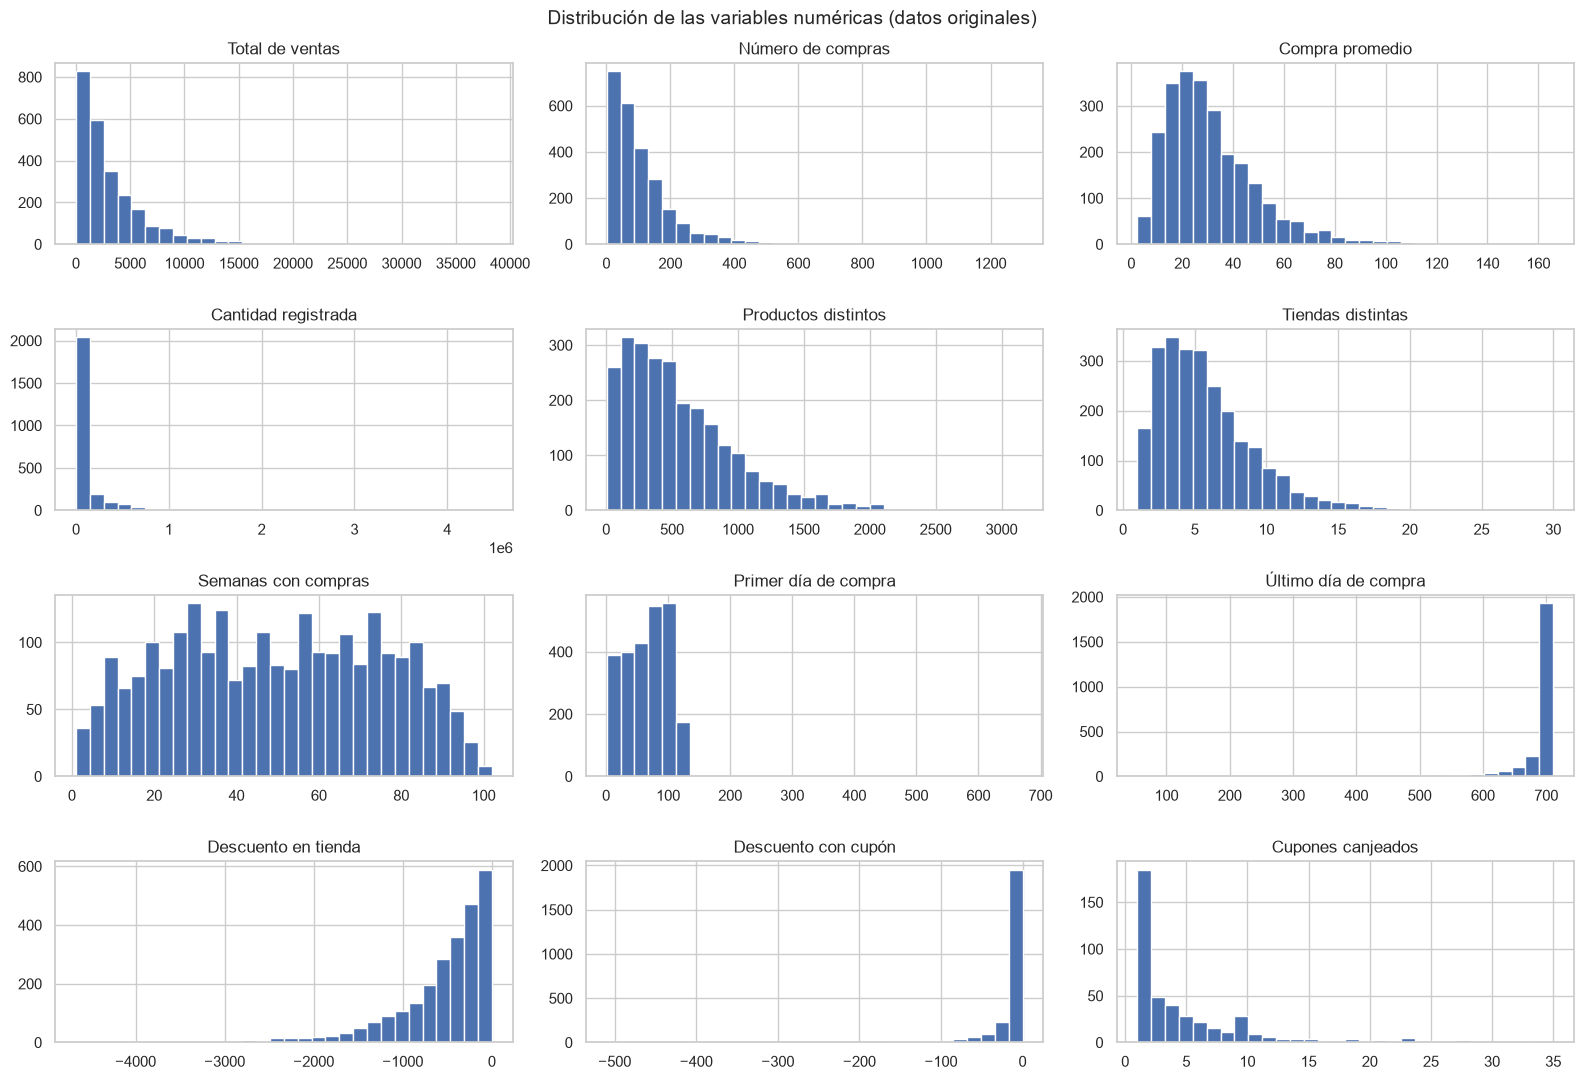

In [14]:
df.drop(columns="household_key").rename(columns=etiqueta_grafico).hist(
    bins=30, figsize=(16, 11), edgecolor="white")
plt.suptitle("Distribución de las variables numéricas (datos originales)", fontsize=14)
plt.tight_layout()
plt.show()

**Lo que muestra la revisión inicial**

* Hay 2.500 hogares y 21 columnas: un identificador, siete variables demográficas, doce métricas de compra y el departamento principal (`top_department`).
* No hay filas ni identificadores duplicados.
* Las variables demográficas y `coupons_redeemed` tienen valores faltantes. Más adelante se revisa qué significan esos nulos.
* Varias métricas tienen una cola larga hacia los valores altos. En `total_quantity`, por ejemplo, la media ronda los 104 mil y la mediana los 11 mil. Esa diferencia merece revisarse antes de interpretar la variable.
* Los descuentos se registran con signo negativo porque se restan del precio.
* En cerca del 95 % de los hogares, `GROCERY` es el departamento con mayor gasto.

## 4. Nombres de las columnas en español

Los nombres se cambian con un diccionario. Se mantienen en minúsculas, con guion bajo y sin tildes para usarlos en el código. En los gráficos se muestran etiquetas legibles en español.

También se traducen los códigos de estado civil: `A` corresponde a casado, `B` a soltero y `U` a desconocido.

In [15]:
nombres_es = {
    "household_key":       "id_hogar",
    "age_desc":            "rango_edad",
    "marital_status_code": "estado_civil",
    "income_desc":         "rango_ingreso",
    "homeowner_desc":      "tipo_vivienda",
    "hh_comp_desc":        "composicion_hogar",
    "household_size_desc": "tamano_hogar",
    "kid_category_desc":   "cantidad_hijos",
    "total_sales":         "total_ventas",
    "num_baskets":         "cantidad_compras",
    "avg_basket_value":    "ticket_promedio",
    "total_quantity":      "cantidad_articulos",
    "distinct_products":   "productos_distintos",
    "distinct_stores":     "tiendas_distintas",
    "active_weeks":        "semanas_activas",
    "first_day":           "primer_dia_compra",
    "last_day":            "ultimo_dia_compra",
    "total_retail_disc":   "descuento_tienda",
    "total_coupon_disc":   "descuento_cupon",
    "coupons_redeemed":    "cupones_canjeados",
    "top_department":      "departamento_principal",
}
df = df.rename(columns=nombres_es)

df["estado_civil"] = df["estado_civil"].map({"A": "Casado", "B": "Soltero", "U": "Desconocido"})

pd.DataFrame({"original": list(nombres_es.keys()), "español": list(nombres_es.values())})

,original,español
0,household_key,id_hogar
1,age_desc,rango_edad
2,marital_status_code,estado_civil
3,income_desc,rango_ingreso
4,homeowner_desc,tipo_vivienda
5,hh_comp_desc,composicion_hogar
6,household_size_desc,tamano_hogar
7,kid_category_desc,cantidad_hijos
8,total_sales,total_ventas
9,num_baskets,cantidad_compras


In [16]:
df.head(3)

,id_hogar,rango_edad,estado_civil,rango_ingreso,tipo_vivienda,composicion_hogar,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,cantidad_articulos,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,departamento_principal
0,1,65+,Casado,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,"4,330.16",86,50.35,1997,677,2,68,51,706,-697.04,-80.56,5.00,GROCERY
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,954.34",45,43.43,834,546,5,35,103,668,-334.99,-9.00,NaN,GROCERY
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2,653.21",47,56.45,8540,516,3,37,113,703,-675.16,-61.19,NaN,GROCERY


In [17]:
# Grupos de columnas que se reutilizan en el resto del notebook
COLS_DEMOGRAFICAS = ["rango_edad", "estado_civil", "rango_ingreso", "tipo_vivienda",
                     "composicion_hogar", "tamano_hogar", "cantidad_hijos"]
COLS_NUMERICAS = ["total_ventas", "cantidad_compras", "ticket_promedio", "cantidad_articulos",
                  "productos_distintos", "tiendas_distintas", "semanas_activas",
                  "primer_dia_compra", "ultimo_dia_compra", "descuento_tienda",
                  "descuento_cupon", "cupones_canjeados"]

## 5. Valores nulos

### 5.1 Conteo y porcentaje por columna

In [18]:
resumen_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("nulos", ascending=False)

print(f"Total de celdas nulas: {df.isna().sum().sum():,} de {df.size:,} "
      f"({df.isna().sum().sum() / df.size:.1%})")
resumen_nulos[resumen_nulos["nulos"] > 0]

Total de celdas nulas: 13,959 de 52,500 (26.6%)


,nulos,porcentaje
cupones_canjeados,2066,82.64
rango_ingreso,1699,67.96
estado_civil,1699,67.96
tipo_vivienda,1699,67.96
rango_edad,1699,67.96
cantidad_hijos,1699,67.96
composicion_hogar,1699,67.96
tamano_hogar,1699,67.96


### 5.2 Porcentaje de nulos por variable

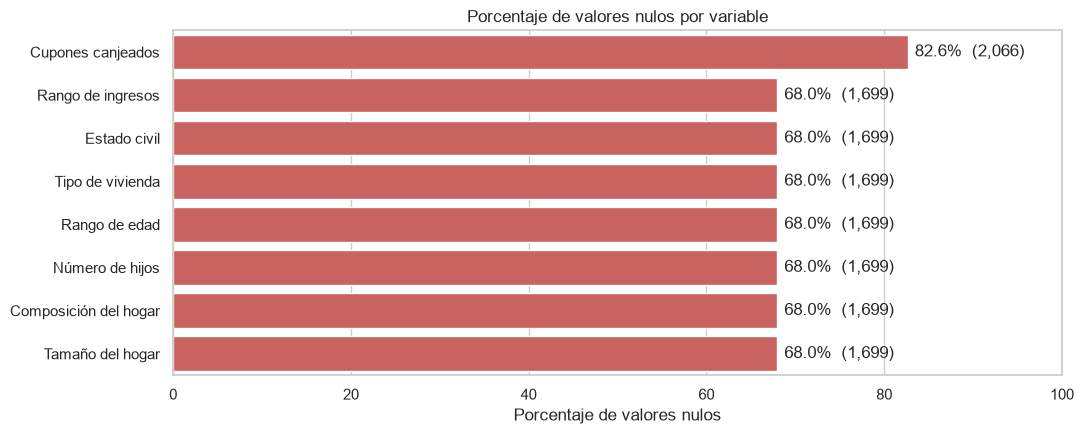

In [19]:
con_nulos = resumen_nulos[resumen_nulos["nulos"] > 0]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=con_nulos["porcentaje"].to_numpy(),
            y=[etiqueta_grafico(col) for col in con_nulos.index],
            color="#d9534f", ax=ax)
for i, (n, p) in enumerate(zip(con_nulos["nulos"], con_nulos["porcentaje"])):
    ax.text(p + 0.8, i, f"{p:.1f}%  ({n:,})", va="center")
ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de valores nulos")
ax.set_ylabel("")
ax.set_title("Porcentaje de valores nulos por variable")
plt.tight_layout()
plt.show()

### 5.3 Matriz de nulidad

Las franjas blancas señalan los datos faltantes. El gráfico permite ver si los nulos se concentran en las mismas filas.

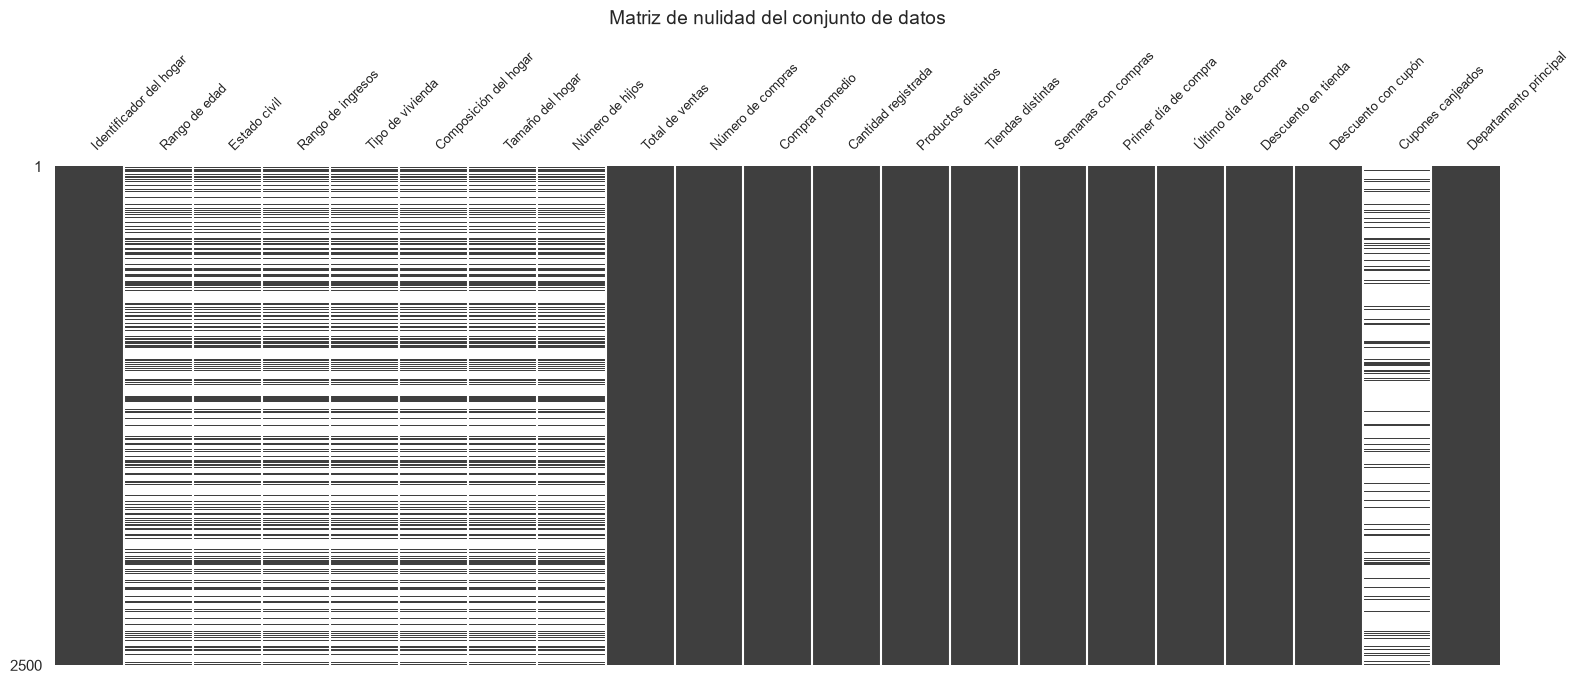

In [20]:
ax = msno.matrix(df.rename(columns=etiqueta_grafico), figsize=(16, 7),
                 fontsize=9, sparkline=False)
ax.set_title("Matriz de nulidad del conjunto de datos", fontsize=14, pad=18)
plt.tight_layout()
plt.show()

### 5.4 Relación entre los datos faltantes

El mapa muestra si los nulos de distintas columnas aparecen juntos. Un valor de 1 indica que coinciden en las mismas filas.

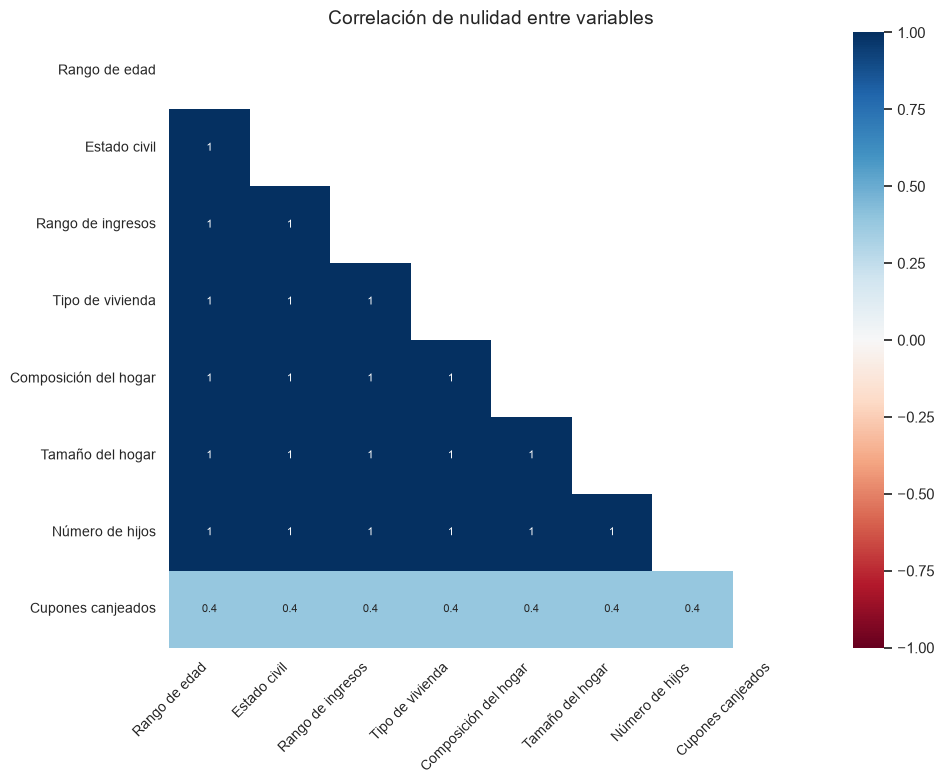

In [21]:
ax = msno.heatmap(df.rename(columns=etiqueta_grafico), figsize=(10, 8), fontsize=10)
ax.grid(False)
ax.set_title("Correlación de nulidad entre variables", fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
# Verificación numérica: ¿las 7 columnas demográficas faltan siempre en las mismas filas?
falta_alguna = df[COLS_DEMOGRAFICAS].isna().any(axis=1)
faltan_todas = df[COLS_DEMOGRAFICAS].isna().all(axis=1)
print("Hogares sin ningún dato demográfico:", faltan_todas.sum())
print("¿Los nulos demográficos coinciden siempre en bloque?:", (falta_alguna == faltan_todas).all())

# ¿Los nulos de cupones_canjeados son hogares que sí compraron?
nulos_cupon = df["cupones_canjeados"].isna()
print("\nHogares con cupones_canjeados nulo:", nulos_cupon.sum())
print("De ellos, con compras registradas (cantidad_compras > 0):",
      (df.loc[nulos_cupon, "cantidad_compras"] > 0).sum())

Hogares sin ningún dato demográfico: 1699
¿Los nulos demográficos coinciden siempre en bloque?: True

Hogares con cupones_canjeados nulo: 2066
De ellos, con compras registradas (cantidad_compras > 0): 2066


**Qué significan los nulos**

1. **Datos demográficos:** las siete columnas tienen 1.699 nulos cada una, un 67,96 %. Faltan juntas: hay 801 hogares con información demográfica y 1.699 sin ella. En el DW estos faltantes se habían rellenado con `"No informado"`; la consulta los convierte de nuevo en `NULL` para poder identificarlos.
2. **Cupones canjeados:** hay 2.066 nulos, un 82,64 %. Proceden del `LEFT JOIN` con `coupon_redempt`: esos hogares no tienen canjes registrados en la tabla. Para el conteo utilizado en este análisis, el valor que corresponde es 0.
3. **Relación entre ambos casos:** el 92,8 % de los hogares sin demografía no tiene canjes registrados, frente al 61,2 % de los hogares con demografía. La correlación de nulidad es cercana a 0,39. Esto muestra una asociación entre la falta de información demográfica y la ausencia de canjes registrados; no demuestra una relación causal.
4. **Métricas de compra:** no tienen nulos y todos los hogares registran al menos una compra.

Por estas diferencias, las columnas demográficas y el conteo de cupones se tratan por separado.

## 6. Valores atípicos

Para detectar los extremos se usa el rango intercuartílico (IQR). Se marca como atípico cualquier valor fuera de $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$. También se calcula la asimetría de cada variable para revisar la forma de su distribución.

In [23]:
def detectar_atipicos_iqr(datos, columnas, factor=1.5):
    '''Devuelve, por columna, los límites IQR y la cantidad/porcentaje de valores atípicos.'''
    filas = []
    for col in columnas:
        serie = datos[col].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - factor * iqr, q3 + factor * iqr
        n_atip = ((serie < lim_inf) | (serie > lim_sup)).sum()
        filas.append({"variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                      "lim_inferior": lim_inf, "lim_superior": lim_sup,
                      "minimo": serie.min(), "maximo": serie.max(),
                      "atipicos": n_atip, "%_atipicos": 100 * n_atip / len(serie),
                      "asimetria": serie.skew()})
    return pd.DataFrame(filas).set_index("variable")

tabla_atipicos = detectar_atipicos_iqr(df, COLS_NUMERICAS)
tabla_atipicos.sort_values("%_atipicos", ascending=False)

,Q1,Q3,IQR,lim_inferior,lim_superior,minimo,maximo,atipicos,%_atipicos,asimetria
variable,,,,,,,,,,
cantidad_articulos,770.00,"87,640.00","86,870.00","-129,535.00","217,945.00",5.00,"4,479,917.00",359,14.36,5.80
ultimo_dia_compra,691.00,710.00,19.00,662.50,738.50,54.00,711.00,326,13.04,-5.57
descuento_cupon,-14.21,0.00,14.21,-35.51,21.31,-509.83,0.00,304,12.16,-5.56
cupones_canjeados,1.00,7.00,6.00,-8.00,16.00,1.00,35.00,27,6.22,2.32
cantidad_compras,39.00,142.25,103.25,-115.88,297.12,1.00,"1,300.00",148,5.92,3.37
descuento_tienda,-756.62,-165.08,591.54,"-1,643.93",722.23,"-4,668.59",-0.25,129,5.16,-2.12
total_ventas,970.74,"4,413.32","3,442.58","-4,193.13","9,577.19",8.17,"38,319.79",127,5.08,2.41
ticket_promedio,18.33,40.55,22.22,-15.00,73.88,2.39,165.83,90,3.60,1.72
tiendas_distintas,3.00,7.00,4.00,-3.00,13.00,1.00,30.00,80,3.20,1.46


### 6.1 Diagramas de caja

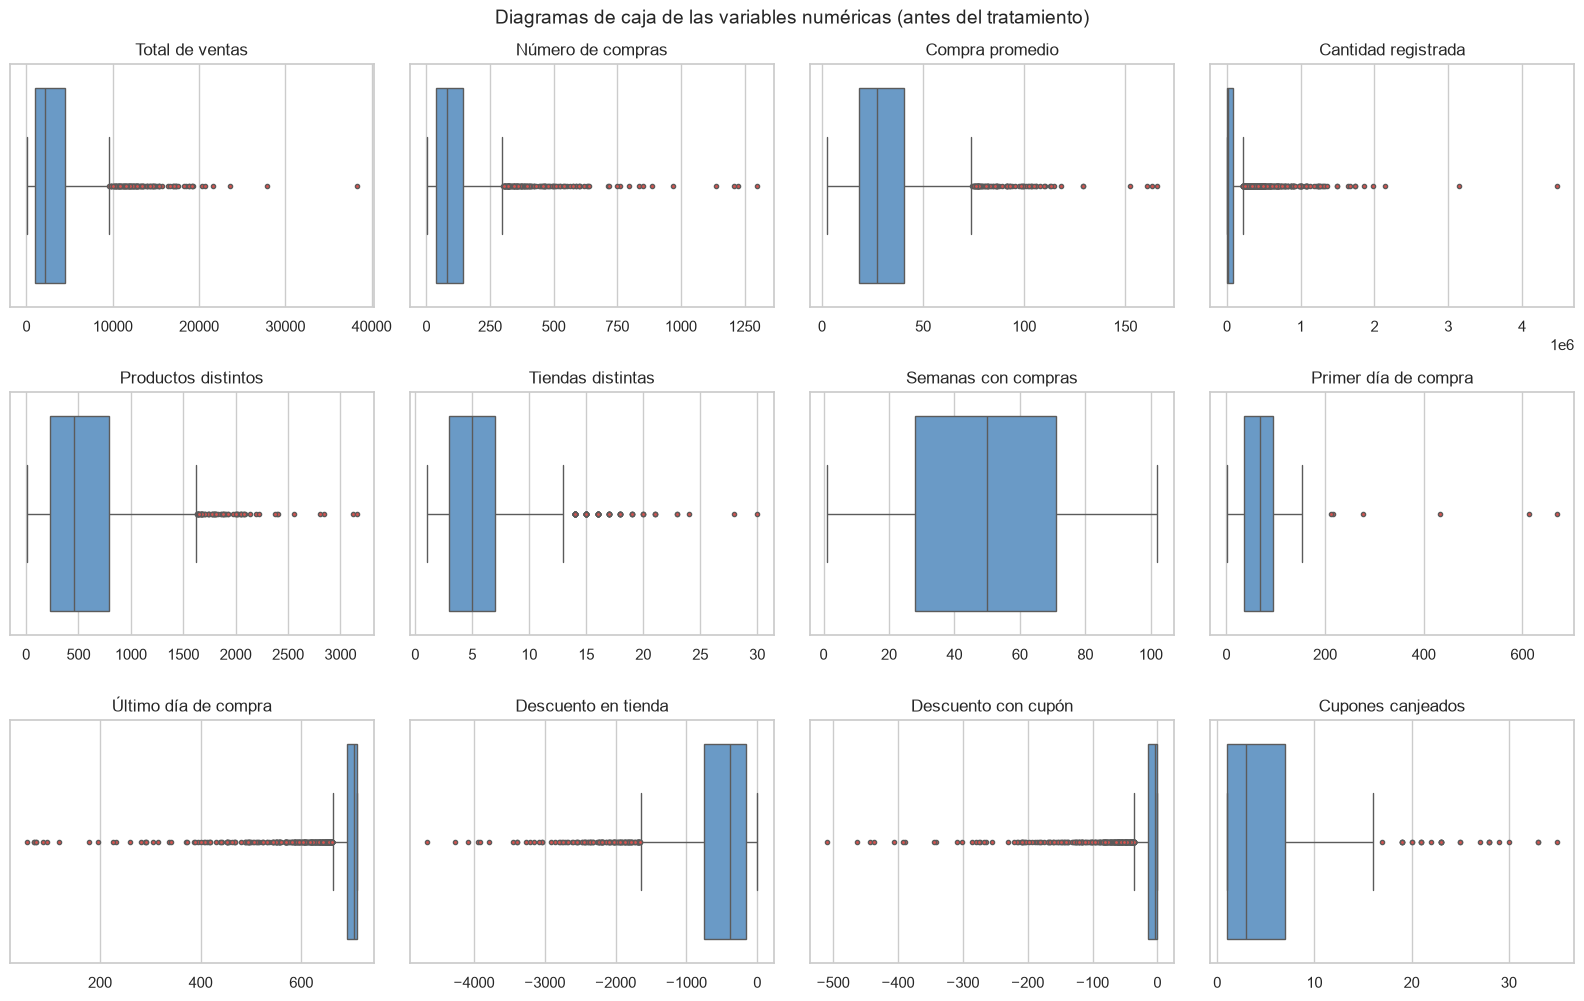

In [24]:
def graficar_boxplots(datos, columnas, titulo, color="#5b9bd5"):
    n = len(columnas)
    ncols = 4
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows))
    for ax, col in zip(axes.flat, columnas):
        sns.boxplot(x=datos[col], ax=ax, color=color,
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#d9534f"})
        ax.set_title(etiqueta_grafico(col))
        ax.set_xlabel("")
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

graficar_boxplots(df, COLS_NUMERICAS, "Diagramas de caja de las variables numéricas (antes del tratamiento)")

### 6.2 Cantidad de valores atípicos por variable

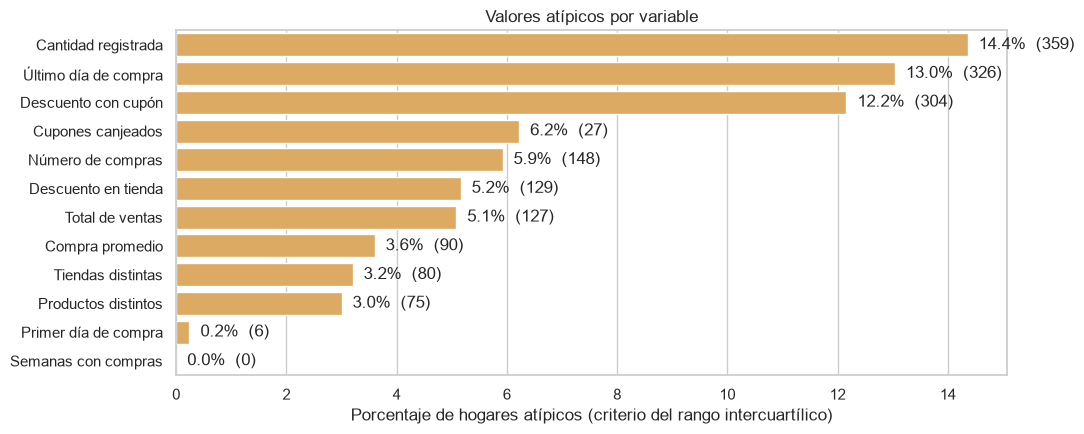

In [25]:
orden = tabla_atipicos.sort_values("%_atipicos", ascending=False)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=orden["%_atipicos"].to_numpy(),
            y=[etiqueta_grafico(col) for col in orden.index],
            color="#f0ad4e", ax=ax)
for i, (n, p) in enumerate(zip(orden["atipicos"], orden["%_atipicos"])):
    ax.text(p + 0.2, i, f"{p:.1f}%  ({n})", va="center")
ax.set_xlabel("Porcentaje de hogares atípicos (criterio del rango intercuartílico)")
ax.set_ylabel("")
ax.set_title("Valores atípicos por variable")
plt.tight_layout()
plt.show()

### 6.3 Revisión de `cantidad_articulos`

El máximo de esta columna ronda los 4,5 millones. Antes de considerarlo un número de artículos, hace falta revisar qué cantidades se están sumando. Los gráficos siguientes comparan la variable con las ventas y con el departamento principal del hogar.

El departamento principal solo indica dónde gastó más cada hogar. No muestra todos los departamentos en los que compró ni permite convertir las unidades de las transacciones.

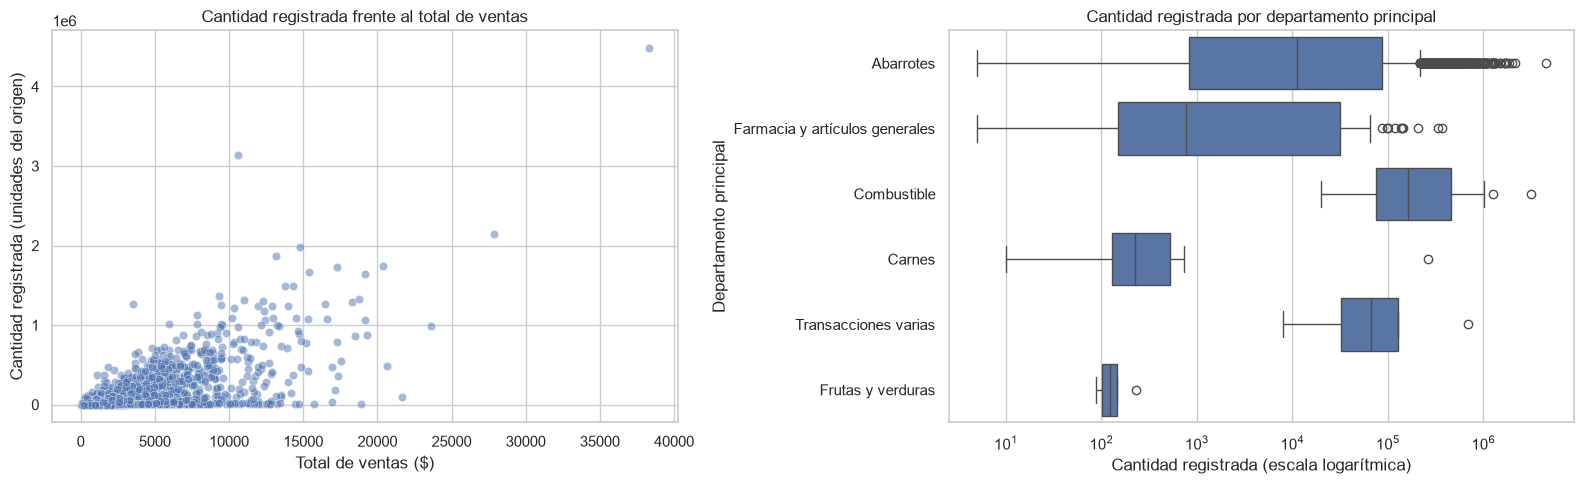

                      count       mean        std  min       50%        90%        95%          99%          max
cantidad_articulos 2,500.00 104,274.25 244,456.08 5.00 11,084.50 329,406.00 529,429.70 1,090,772.69 4,479,917.00


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=df, x="total_ventas", y="cantidad_articulos", alpha=0.5, ax=axes[0])
axes[0].set_title("Cantidad registrada frente al total de ventas")
axes[0].set_xlabel("Total de ventas ($)")
axes[0].set_ylabel("Cantidad registrada (unidades del origen)")

# Se traducen los departamentos en una copia destinada al gráfico.
datos_departamentos = df[["cantidad_articulos", "departamento_principal"]].copy()
datos_departamentos["departamento_principal"] = (
    datos_departamentos["departamento_principal"].map(ETIQUETAS_CATEGORIAS))
orden_departamentos = [ETIQUETAS_CATEGORIAS[departamento]
                       for departamento in df["departamento_principal"].value_counts().index[:6]]
sns.boxplot(data=datos_departamentos, x="cantidad_articulos", y="departamento_principal",
            ax=axes[1], order=orden_departamentos)
axes[1].set_xscale("log")
axes[1].set_title("Cantidad registrada por departamento principal")
axes[1].set_xlabel("Cantidad registrada (escala logarítmica)")
axes[1].set_ylabel("Departamento principal")
plt.tight_layout()
plt.show()

print(df[["cantidad_articulos"]].describe(percentiles=[.5, .9, .95, .99]).T)

**Qué se observa en los extremos**

* Varias métricas tienen valores altos alejados de la mayoría. Pueden corresponder a hogares con mayor actividad, así que un valor atípico no basta para descartar un registro. En los descuentos, los extremos aparecen hacia el lado negativo por la forma en que se guardan en el origen.
* `cantidad_articulos` tiene alrededor de un 14 % de atípicos y una asimetría de 5,8. La consulta suma `QUANTITY` de todos los departamentos, incluidos combustible (`KIOSK-GAS`) y transacciones varias (`MISC SALES TRAN`). Como no hay una unidad común documentada, esa suma no se puede interpretar como un conteo de artículos. Recortar los valores altos no resuelve la diferencia de unidades. Por eso la columna se conserva en el diagnóstico original y se retira del conjunto que se va a procesar.
* `descuento_cupon` tiene muchos extremos según el criterio IQR. Más de una cuarta parte de los hogares tiene descuento 0 y el rango intercuartílico queda estrecho.
* Los extremos de `primer_dia_compra` y `ultimo_dia_compra` pueden reflejar hogares que empezaron a comprar más tarde o dejaron de hacerlo antes. Se conserva esa información.
* `semanas_activas` no presenta atípicos con el criterio utilizado.

El tratamiento se decide por variable. Se mantienen los 2.500 hogares, ya que los gráficos no aportan una razón suficiente para eliminar filas completas.

## 7. Imputación y tratamiento de los datos

Las funciones siguientes permiten aplicar los tratamientos sin modificar `df_original`. Las decisiones se basan en lo observado en las secciones anteriores:

* **Cantidad sin unidad común:** se elimina `cantidad_articulos` del conjunto procesado. Su valor original queda disponible para revisar el problema; no se intentan conversiones sin una equivalencia documentada.
* **Demografía faltante:** primero se crea `tiene_demografia` y después se rellenan los nulos con `"Desconocido"`. También se unifican las etiquetas equivalentes `"Unknown"` y `"U"`. Rellenar con la moda asignaría datos que no se conocen a 1.699 hogares; eliminar las filas haría perder casi el 68 % del conjunto. La categoría y el indicador permiten conservar esos hogares y distinguir los faltantes.
* **Canjes sin registro:** los nulos de `cupones_canjeados` se rellenan con 0, según el significado del conteo obtenido de la tabla de canjes.
* **Extremos de compra:** se acotan siete métricas entre los percentiles 1 y 99. Así se reduce la influencia de los extremos sin quitar hogares. No se recortan todos los casos que señala el IQR, porque las distribuciones son asimétricas y pueden incluir clientes de alta actividad.
* **Primer y último día de compra:** se conservan tal como están, porque aportan información sobre el periodo de actividad de cada hogar.
* **Ventas totales:** se mantienen los valores originales, incluidos los gastos altos, porque esta es la variable que se propone explicar.

In [27]:
def crear_indicador_faltante(datos, columnas, nombre_indicador):
    '''Crea una columna 1/0 que indica si el registro TIENE datos en las columnas dadas.
    Se debe ejecutar ANTES de imputar, para no perder la información de qué era faltante.'''
    datos = datos.copy()
    datos[nombre_indicador] = datos[columnas].notna().all(axis=1).astype(int)
    return datos


def imputar(datos, columnas, estrategia="constante", valor=None):
    '''Imputa valores nulos en las columnas indicadas.
    estrategia: 'constante' (usa `valor`), 'media', 'mediana' o 'moda'.'''
    datos = datos.copy()
    for col in columnas:
        if estrategia == "constante":
            relleno = valor
        elif estrategia == "media":
            relleno = datos[col].mean()
        elif estrategia == "mediana":
            relleno = datos[col].median()
        elif estrategia == "moda":
            relleno = datos[col].mode().iloc[0]
        else:
            raise ValueError(f"Estrategia no soportada: {estrategia}")
        n = datos[col].isna().sum()
        datos[col] = datos[col].fillna(relleno)
        print(f"  {col:<22} -> {n:>5} nulos imputados con {estrategia} = {relleno!r}")
    return datos


def unificar_categoria(datos, columnas, equivalentes, destino="Desconocido"):
    '''Reemplaza etiquetas equivalentes (ej. 'Unknown') por una sola categoría.'''
    datos = datos.copy()
    for col in columnas:
        datos[col] = datos[col].replace(list(equivalentes), destino)
    return datos


def tratar_atipicos(datos, columnas, metodo="percentil", p_inf=0.01, p_sup=0.99, factor=1.5):
    '''Acota (winsoriza) los valores atípicos sin eliminar filas.
    metodo='percentil': acota a los percentiles p_inf y p_sup.
    metodo='iqr'      : acota a Q1 - factor*IQR y Q3 + factor*IQR.'''
    datos = datos.copy()
    for col in columnas:
        if metodo == "percentil":
            lim_inf, lim_sup = datos[col].quantile([p_inf, p_sup])
        elif metodo == "iqr":
            q1, q3 = datos[col].quantile([0.25, 0.75])
            lim_inf, lim_sup = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)
        else:
            raise ValueError(f"Método no soportado: {metodo}")
        n = ((datos[col] < lim_inf) | (datos[col] > lim_sup)).sum()
        datos[col] = datos[col].clip(lim_inf, lim_sup)
        print(f"  {col:<22} -> {n:>4} valores acotados a [{lim_inf:,.2f}, {lim_sup:,.2f}]")
    return datos

### 7.1 Retiro de la cantidad sin unidad común

`cantidad_articulos` se retira antes de las transformaciones. `df_original` conserva las 21 columnas de entrada y los gráficos anteriores muestran el motivo de esta decisión.

In [28]:
df = df.drop(columns="cantidad_articulos")
COLS_NUMERICAS = [col for col in COLS_NUMERICAS if col != "cantidad_articulos"]
print("Variable retirada: cantidad_articulos (unidad no homogénea)")
print(f"Hogares conservados: {len(df):,} | Columnas antes de imputar: {df.shape[1]}")

Variable retirada: cantidad_articulos (unidad no homogénea)
Hogares conservados: 2,500 | Columnas antes de imputar: 20


### 7.2 Tratamiento de los nulos

In [29]:
df = crear_indicador_faltante(df, COLS_DEMOGRAFICAS, "tiene_demografia")
print("Hogares con demografía:", df["tiene_demografia"].sum(), "| sin demografía:",
      (df["tiene_demografia"] == 0).sum(), "\n")

print("Imputación de variables demográficas:")
df = imputar(df, COLS_DEMOGRAFICAS, estrategia="constante", valor="Desconocido")
df = unificar_categoria(df, ["tipo_vivienda", "composicion_hogar"], equivalentes=["Unknown"])

print("\nImputación de cupones canjeados:")
df = imputar(df, ["cupones_canjeados"], estrategia="constante", valor=0)

print("\nNulos restantes en el dataset:", df.isna().sum().sum())

Hogares con demografía: 801 | sin demografía: 1699 

Imputación de variables demográficas:
  rango_edad             ->  1699 nulos imputados con constante = 'Desconocido'
  estado_civil           ->  1699 nulos imputados con constante = 'Desconocido'
  rango_ingreso          ->  1699 nulos imputados con constante = 'Desconocido'
  tipo_vivienda          ->  1699 nulos imputados con constante = 'Desconocido'
  composicion_hogar      ->  1699 nulos imputados con constante = 'Desconocido'
  tamano_hogar           ->  1699 nulos imputados con constante = 'Desconocido'
  cantidad_hijos         ->  1699 nulos imputados con constante = 'Desconocido'

Imputación de cupones canjeados:
  cupones_canjeados      ->  2066 nulos imputados con constante = 0

Nulos restantes en el dataset: 0


### 7.3 Tratamiento de los extremos

In [30]:
COLS_ACOTAR = ["cantidad_compras", "ticket_promedio", "productos_distintos",
               "tiendas_distintas", "descuento_tienda", "descuento_cupon", "cupones_canjeados"]

df_antes_atipicos = df.copy()
df = tratar_atipicos(df, COLS_ACOTAR, metodo="percentil", p_inf=0.01, p_sup=0.99)

  cantidad_compras       ->   48 valores acotados a [5.00, 553.10]
  ticket_promedio        ->   50 valores acotados a [6.20, 99.03]
  productos_distintos    ->   47 valores acotados a [22.00, 1,973.21]
  tiendas_distintas      ->   22 valores acotados a [1.00, 17.00]
  descuento_tienda       ->   50 valores acotados a [-2,606.62, -10.19]
  descuento_cupon        ->   25 valores acotados a [-208.06, 0.00]
  cupones_canjeados      ->   22 valores acotados a [0.00, 19.00]


### 7.4 Comparación antes y después

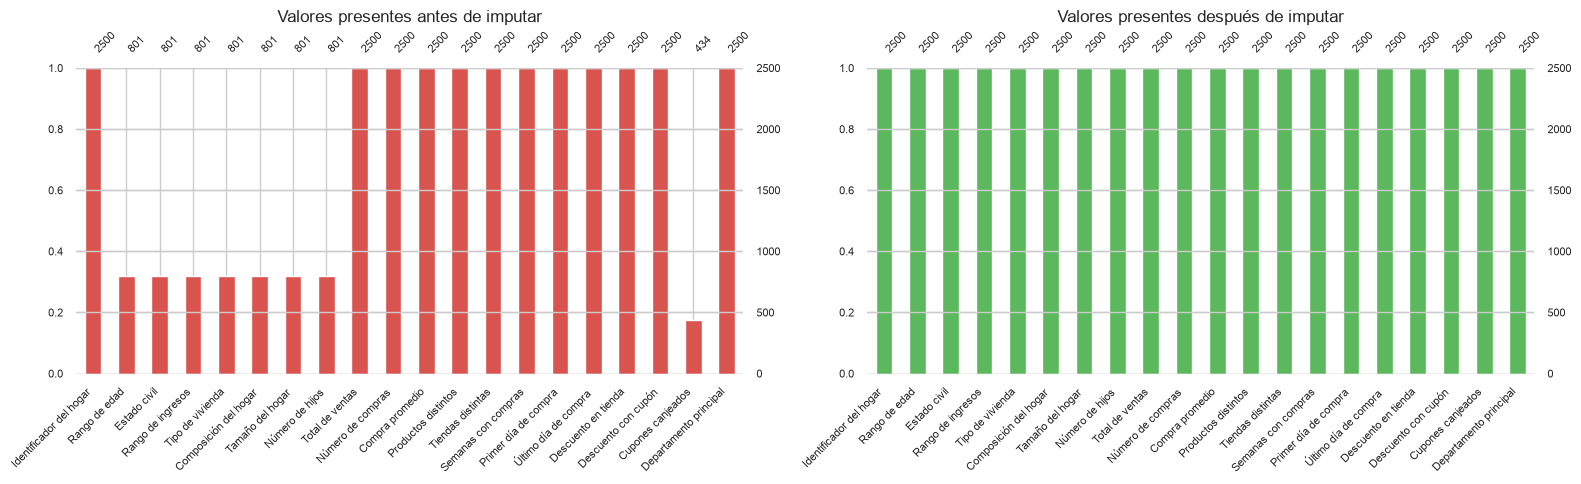

In [31]:
# Se comparan las mismas variables conservadas en ambos gráficos.
columnas_comparables = df.drop(columns="tiene_demografia").columns
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
msno.bar(df_original.rename(columns=nombres_es)[columnas_comparables]
         .rename(columns=etiqueta_grafico), ax=axes[0], fontsize=8, color="#d9534f")
axes[0].set_title("Valores presentes antes de imputar")
msno.bar(df[columnas_comparables].rename(columns=etiqueta_grafico),
         ax=axes[1], fontsize=8, color="#5cb85c")
axes[1].set_title("Valores presentes después de imputar")
plt.tight_layout()
plt.show()

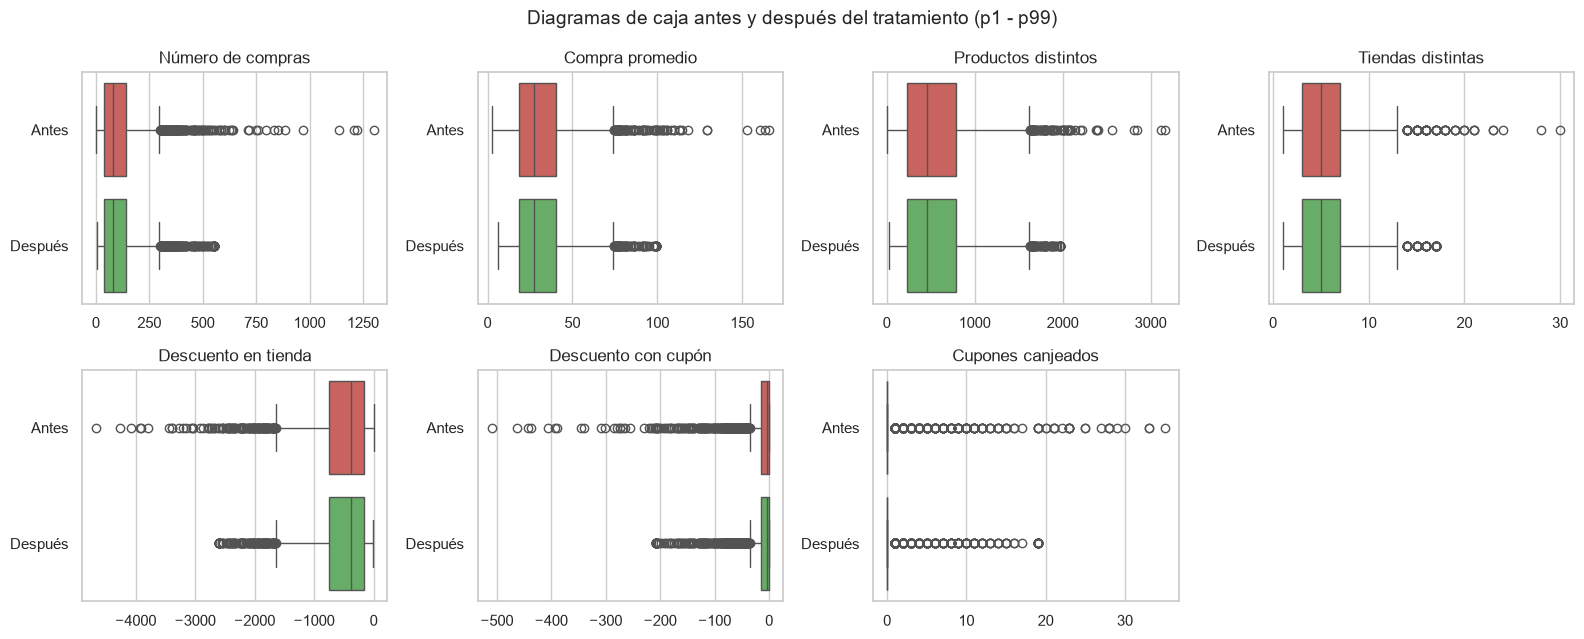

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, col in enumerate(COLS_ACOTAR):
    ax = axes.flat[i]
    comparacion = pd.DataFrame({"Antes": df_antes_atipicos[col], "Después": df[col]}).melt(
        var_name="estado", value_name=col)
    sns.boxplot(data=comparacion, x=col, y="estado", hue="estado", ax=ax,
                palette=["#d9534f", "#5cb85c"], legend=False)
    ax.set_title(etiqueta_grafico(col))
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in list(axes.flat)[len(COLS_ACOTAR):]:
    ax.set_visible(False)
fig.suptitle("Diagramas de caja antes y después del tratamiento (p1 - p99)", fontsize=14)
plt.tight_layout()
plt.show()

In [33]:
pd.DataFrame({
    "max_antes": df_antes_atipicos[COLS_ACOTAR].max(),
    "max_despues": df[COLS_ACOTAR].max(),
    "asimetria_antes": df_antes_atipicos[COLS_ACOTAR].skew(),
    "asimetria_despues": df[COLS_ACOTAR].skew(),
})

,max_antes,max_despues,asimetria_antes,asimetria_despues
cantidad_compras,"1,300.00",553.10,3.37,1.99
ticket_promedio,165.83,99.03,1.72,1.29
productos_distintos,"3,159.00","1,973.21",1.36,1.13
tiendas_distintas,30.00,17.00,1.46,1.11
descuento_tienda,-0.25,-10.19,-2.12,-1.66
descuento_cupon,0.00,0.00,-5.56,-3.72
cupones_canjeados,35.00,19.00,5.55,4.43


Después del tratamiento quedan los mismos 2.500 hogares y ya no hay nulos. `cantidad_articulos` se ha retirado por la diferencia de unidades.

El acotamiento se aplica a las siete métricas de `COLS_ACOTAR`. Por ejemplo, el máximo de `cantidad_compras` baja de 1.300 a unos 553. Los diagramas permiten revisar cuánto cambia cada distribución. Todavía puede haber atípicos según el IQR, porque el objetivo de este paso es limitar los extremos, no hacer que desaparezcan todos.

## 8. Tipos de datos

Cada columna se convierte al tipo que corresponde a su uso:

* `id_hogar` pasa a texto, porque identifica al hogar y no se usa como una cantidad.
* Las variables demográficas y `departamento_principal` pasan a `category`. Los rangos de edad e ingreso, el tamaño del hogar y la cantidad de hijos se definen como categorías ordenadas.
* Los conteos y los días pasan a enteros. Después de acotar los extremos, algunos límites tienen decimales; por eso se redondean antes de convertirlos.
* Los montos se mantienen como decimales con dos cifras. Los descuentos pasan a valores positivos para representar el monto ahorrado.

Al final se comprueba que la conversión de categorías no haya creado nulos nuevos.

In [34]:
tipos_antes = df.dtypes.astype(str)

ORDEN_EDAD = ["Desconocido", "19-24", "25-34", "35-44", "45-54", "55-64", "65+"]
ORDEN_INGRESO = ["Desconocido", "Under 15K", "15-24K", "25-34K", "35-49K", "50-74K", "75-99K",
                 "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"]
ORDEN_TAMANO = ["Desconocido", "1", "2", "3", "4", "5+"]
ORDEN_HIJOS = ["Desconocido", "None/Unknown", "1", "2", "3+"]

df["id_hogar"] = df["id_hogar"].astype("string")

df["rango_edad"] = pd.Categorical(df["rango_edad"], categories=ORDEN_EDAD, ordered=True)
df["rango_ingreso"] = pd.Categorical(df["rango_ingreso"], categories=ORDEN_INGRESO, ordered=True)
df["tamano_hogar"] = pd.Categorical(df["tamano_hogar"].astype(str), categories=ORDEN_TAMANO, ordered=True)
df["cantidad_hijos"] = pd.Categorical(df["cantidad_hijos"], categories=ORDEN_HIJOS, ordered=True)
for col in ["estado_civil", "tipo_vivienda", "composicion_hogar", "departamento_principal"]:
    df[col] = df[col].astype("category")

COLS_ENTERAS = ["cantidad_compras", "productos_distintos", "tiendas_distintas",
                "semanas_activas", "primer_dia_compra", "ultimo_dia_compra", "cupones_canjeados"]
df[COLS_ENTERAS] = df[COLS_ENTERAS].round().astype("int64")

df["descuento_tienda"] = df["descuento_tienda"].abs()
df["descuento_cupon"] = df["descuento_cupon"].abs()
COLS_MONTOS = ["total_ventas", "ticket_promedio", "descuento_tienda", "descuento_cupon"]
df[COLS_MONTOS] = df[COLS_MONTOS].astype("float64").round(2)

# Ninguna categoría debe haber quedado sin asignar (NaN) al convertir
assert df.isna().sum().sum() == 0, "Hay valores fuera de las categorías definidas"

pd.DataFrame({"tipo_antes": tipos_antes, "tipo_despues": df.dtypes.astype(str)})

,tipo_antes,tipo_despues
id_hogar,int64,string
rango_edad,str,category
estado_civil,str,category
rango_ingreso,str,category
tipo_vivienda,str,category
composicion_hogar,str,category
tamano_hogar,str,category
cantidad_hijos,str,category
total_ventas,float64,float64
cantidad_compras,float64,int64


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   id_hogar                2500 non-null   string  
 1   rango_edad              2500 non-null   category
 2   estado_civil            2500 non-null   category
 3   rango_ingreso           2500 non-null   category
 4   tipo_vivienda           2500 non-null   category
 5   composicion_hogar       2500 non-null   category
 6   tamano_hogar            2500 non-null   category
 7   cantidad_hijos          2500 non-null   category
 8   total_ventas            2500 non-null   float64 
 9   cantidad_compras        2500 non-null   int64   
 10  ticket_promedio         2500 non-null   float64 
 11  productos_distintos     2500 non-null   int64   
 12  tiendas_distintas       2500 non-null   int64   
 13  semanas_activas         2500 non-null   int64   
 14  primer_dia_compra       2500 non-nu

## 9. Conversión de categorías a números

La codificación depende de si la variable tiene un orden natural:

**Variables ordinales.** En `rango_edad`, `rango_ingreso`, `tamano_hogar` y `cantidad_hijos` se asignan números que respetan el orden de las categorías. Por ejemplo, los ingresos van de `Under 15K` = 1 a `250K+` = 12. Estos números representan posiciones, no distancias iguales entre rangos.

`Desconocido` se codifica como 0 y se conserva `tiene_demografia` para distinguir los hogares sin datos. En `cantidad_hijos`, `None/Unknown` también recibe el código 0. Es una convención para esta categoría: suele coincidir con hogares sin hijos, pero no confirma que todos esos hogares tengan cero hijos.

**Variables nominales.** En estado civil, vivienda, composición del hogar y departamento principal se crea una columna 0/1 por categoría con `get_dummies`. Se usa `drop_first=True` para quitar una categoría de referencia y evitar la dependencia exacta entre todas las columnas de una misma variable. Los departamentos con menos del 1 % de los hogares se agrupan en `OTROS`, para no crear columnas con muy pocos casos.

In [36]:
MAPEO_ORDINAL = {
    "rango_edad":     {c: i for i, c in enumerate(ORDEN_EDAD)},
    "rango_ingreso":  {c: i for i, c in enumerate(ORDEN_INGRESO)},
    "tamano_hogar":   {c: i for i, c in enumerate(ORDEN_TAMANO)},
    "cantidad_hijos": {"Desconocido": 0, "None/Unknown": 0, "1": 1, "2": 2, "3+": 3},
}
for col, mapa in MAPEO_ORDINAL.items():
    print(f"{col}: {mapa}")
    df[col] = df[col].astype(str).map(mapa).astype("int64")

rango_edad: {'Desconocido': 0, '19-24': 1, '25-34': 2, '35-44': 3, '45-54': 4, '55-64': 5, '65+': 6}
rango_ingreso: {'Desconocido': 0, 'Under 15K': 1, '15-24K': 2, '25-34K': 3, '35-49K': 4, '50-74K': 5, '75-99K': 6, '100-124K': 7, '125-149K': 8, '150-174K': 9, '175-199K': 10, '200-249K': 11, '250K+': 12}
tamano_hogar: {'Desconocido': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5+': 5}
cantidad_hijos: {'Desconocido': 0, 'None/Unknown': 0, '1': 1, '2': 2, '3+': 3}


In [37]:
# Agrupar departamentos poco frecuentes (< 1 % de los hogares)
frecuencia = df["departamento_principal"].value_counts(normalize=True)
poco_frecuentes = frecuencia[frecuencia < 0.01].index
df["departamento_principal"] = (df["departamento_principal"].astype(str)
                                .replace(list(poco_frecuentes), "OTROS"))
print("Departamentos agrupados en OTROS:", list(poco_frecuentes))
print(df["departamento_principal"].value_counts().to_string())

Departamentos agrupados en OTROS: ['MEAT', 'MISC SALES TRAN', 'PRODUCE', 'NUTRITION', 'PASTRY', 'DELI', 'SPIRITS', 'COSMETICS', 'MEAT-PCKGD', 'SALAD BAR']
departamento_principal
GROCERY      2380
DRUG GM        63
OTROS          31
KIOSK-GAS      26


In [38]:
COLS_NOMINALES = ["estado_civil", "tipo_vivienda", "composicion_hogar", "departamento_principal"]
df = pd.get_dummies(df, columns=COLS_NOMINALES, drop_first=True, dtype="int64")

print(f"Dimensiones tras la codificación: {df.shape}")
print("\nTipos de datos resultantes:")
print(df.dtypes.value_counts().to_string())
df.head()

Dimensiones tras la codificación: (2500, 31)

Tipos de datos resultantes:
int64      26
float64     4
string      1


,id_hogar,rango_edad,rango_ingreso,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,tiene_demografia,estado_civil_Desconocido,estado_civil_Soltero,tipo_vivienda_Homeowner,tipo_vivienda_Probable Owner,tipo_vivienda_Probable Renter,tipo_vivienda_Renter,composicion_hogar_2 Adults Kids,composicion_hogar_2 Adults No Kids,composicion_hogar_Desconocido,composicion_hogar_Single Female,composicion_hogar_Single Male,departamento_principal_GROCERY,departamento_principal_KIOSK-GAS,departamento_principal_OTROS
0,1,6,4,2,0,"4,330.16",86,50.35,677,2,68,51,706,697.04,80.56,5,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0
1,2,0,0,0,0,"1,954.34",45,43.43,546,5,35,103,668,334.99,9.00,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
2,3,0,0,0,0,"2,653.21",47,56.45,516,3,37,113,703,675.16,61.19,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
3,4,0,0,0,0,"1,200.11",30,40.00,164,6,26,104,627,115.65,2.50,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
4,5,0,0,0,0,779.06,40,19.48,199,3,27,85,703,118.33,0.00,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0


## 10. Estandarización

Las variables tienen escalas distintas: `productos_distintos` llega a miles, mientras que `tiendas_distintas` llega a 17 después del tratamiento. Se usa `StandardScaler` para expresarlas en una escala comparable:

$z = \frac{x - \mu}{\sigma}$

Z-score deja media 0 y desviación poblacional 1. La alternativa Min-Max usa el mínimo y el máximo, que aquí siguen dependiendo de distribuciones asimétricas. La estandarización tampoco elimina la asimetría ni hace que los datos tengan una distribución normal.

Se escalan 14 variables: las métricas de compra conservadas, excepto `total_ventas`, y los cuatro códigos ordinales. El identificador se mantiene como texto, las columnas binarias siguen en 0/1 y las ventas se conservan en dólares.

Este paso prepara los datos del EDA. Si más adelante se evalúa un modelo, el escalado y las demás transformaciones aprendidas tendrán que ajustarse solo con los datos de entrenamiento.

In [39]:
COLS_ORDINALES = list(MAPEO_ORDINAL.keys())
COLS_ESCALAR = COLS_ORDINALES + [c for c in COLS_NUMERICAS if c != "total_ventas"]

df_sin_escalar = df.copy()
escalador = StandardScaler()
df[COLS_ESCALAR] = escalador.fit_transform(df[COLS_ESCALAR])

pd.DataFrame({
    "media_antes": df_sin_escalar[COLS_ESCALAR].mean(),
    "desv_antes": df_sin_escalar[COLS_ESCALAR].std(),
    "media_despues": df[COLS_ESCALAR].mean().round(4),
    "desv_despues": df[COLS_ESCALAR].std().round(4),
})

,media_antes,desv_antes,media_despues,desv_despues
rango_edad,1.12,1.78,-0.00,1.00
rango_ingreso,1.51,2.54,-0.00,1.00
tamano_hogar,0.70,1.23,0.00,1.00
cantidad_hijos,0.18,0.60,0.00,1.00
cantidad_compras,108.40,102.09,0.00,1.00
ticket_promedio,31.46,18.19,0.00,1.00
productos_distintos,557.67,423.60,0.00,1.00
tiendas_distintas,5.43,3.38,-0.00,1.00
semanas_activas,49.59,25.54,-0.00,1.00
primer_dia_compra,65.94,39.15,0.00,1.00


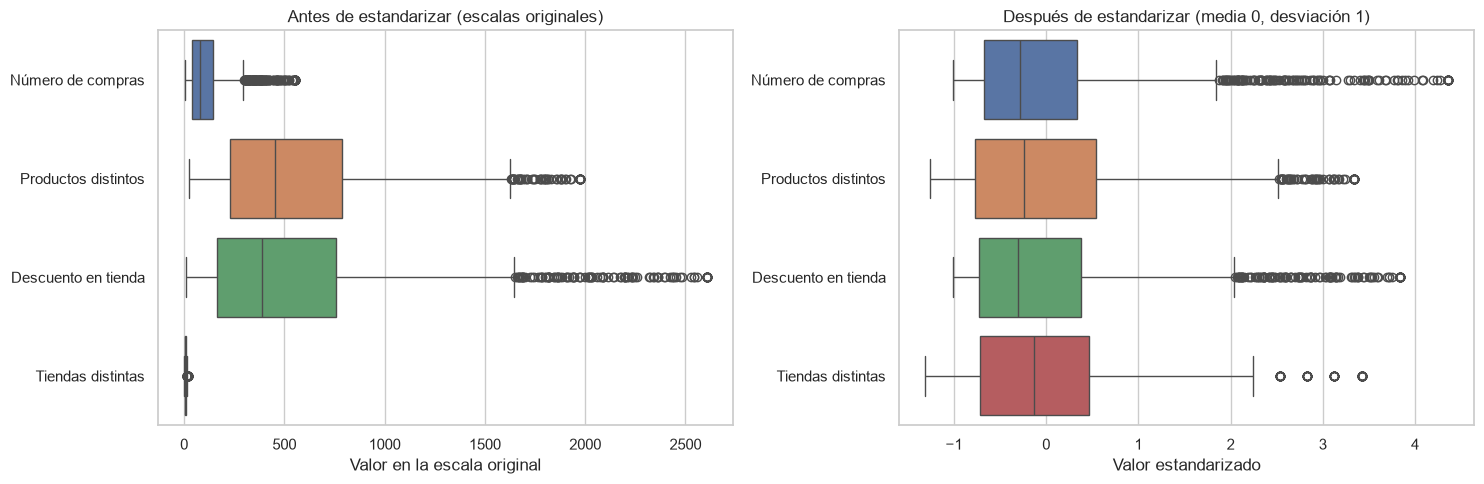

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ejemplo = ["cantidad_compras", "productos_distintos", "descuento_tienda", "tiendas_distintas"]
sns.boxplot(data=df_sin_escalar[ejemplo].rename(columns=etiqueta_grafico),
            orient="h", ax=axes[0])
axes[0].set_title("Antes de estandarizar (escalas originales)")
axes[0].set_xlabel("Valor en la escala original")
sns.boxplot(data=df[ejemplo].rename(columns=etiqueta_grafico), orient="h", ax=axes[1])
axes[1].set_title("Después de estandarizar (media 0, desviación 1)")
axes[1].set_xlabel("Valor estandarizado")
plt.tight_layout()
plt.show()

## 11. Correlación entre variables

La correlación de Pearson permite revisar cómo se relacionan las variables numéricas, los códigos ordinales y el indicador de demografía. Estandarizar no cambia este coeficiente. Las categorías codificadas en columnas 0/1 se incluyen después en la comparación con las ventas.

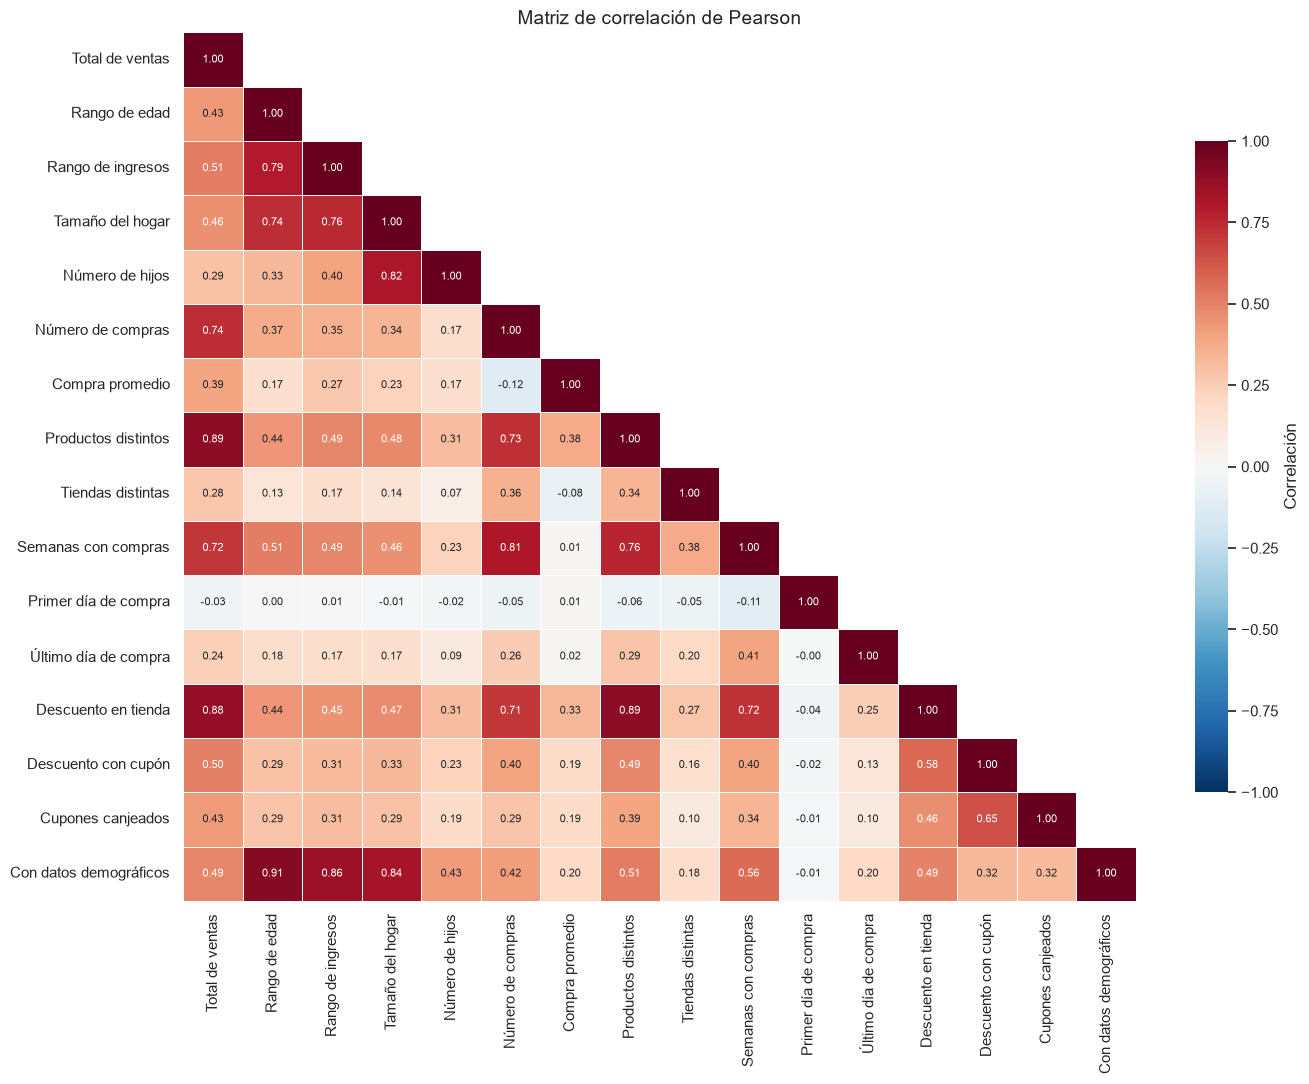

In [41]:
COLS_CORR = ["total_ventas"] + COLS_ESCALAR + ["tiene_demografia"]
matriz_corr = df[COLS_CORR].corr(method="pearson")
matriz_grafico = matriz_corr.rename(index=etiqueta_grafico, columns=etiqueta_grafico)

mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(matriz_grafico, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"shrink": 0.75, "label": "Correlación"}, ax=ax,
            annot_kws={"size": 8})
ax.grid(False)
ax.set_title("Matriz de correlación de Pearson", fontsize=14)
plt.tight_layout()
plt.show()

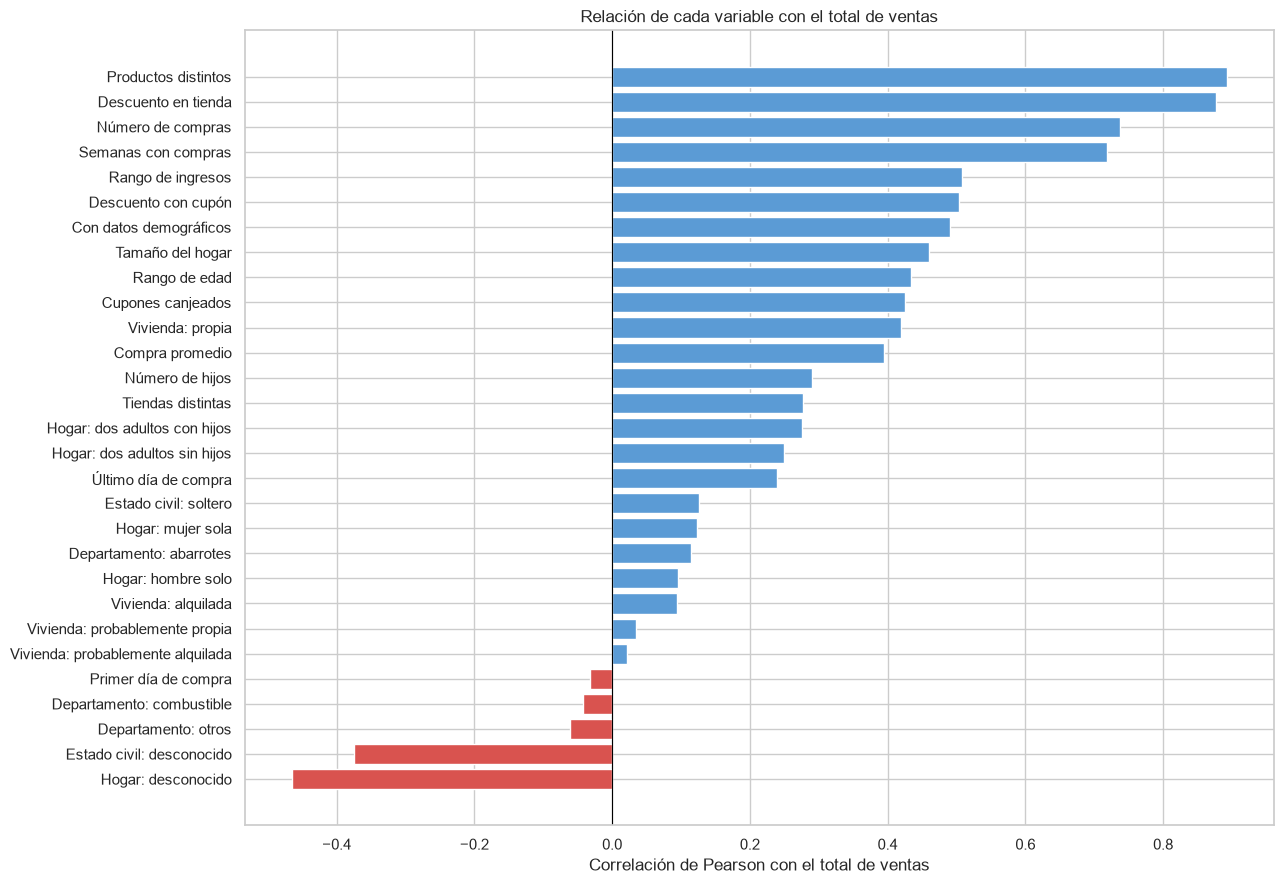

In [42]:
corr_objetivo = df.drop(columns="id_hogar").corr()["total_ventas"].drop("total_ventas").sort_values()
etiquetas_objetivo = [etiqueta_grafico(col) for col in corr_objetivo.index]

fig, ax = plt.subplots(figsize=(13, 9))
colores = ["#d9534f" if v < 0 else "#5b9bd5" for v in corr_objetivo]
ax.barh(etiquetas_objetivo, corr_objetivo.values, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación de Pearson con el total de ventas")
ax.set_title("Relación de cada variable con el total de ventas")
plt.tight_layout()
plt.show()

In [43]:
# Pares de variables explicativas con correlación fuerte (|r| >= 0.7): riesgo de multicolinealidad
pares = (matriz_corr.where(~np.tril(np.ones_like(matriz_corr, dtype=bool)))
         .stack().rename("r").reset_index())
pares.columns = ["variable_1", "variable_2", "r"]
pares[pares["r"].abs() >= 0.7].sort_values("r", key=abs, ascending=False)

,variable_1,variable_2,r
31,rango_edad,tiene_demografia,0.91
124,productos_distintos,descuento_tienda,0.89
7,total_ventas,productos_distintos,0.89
12,total_ventas,descuento_tienda,0.88
47,rango_ingreso,tiene_demografia,0.86
63,tamano_hogar,tiene_demografia,0.84
52,tamano_hogar,cantidad_hijos,0.82
89,cantidad_compras,semanas_activas,0.81
18,rango_edad,rango_ingreso,0.79
121,productos_distintos,semanas_activas,0.76


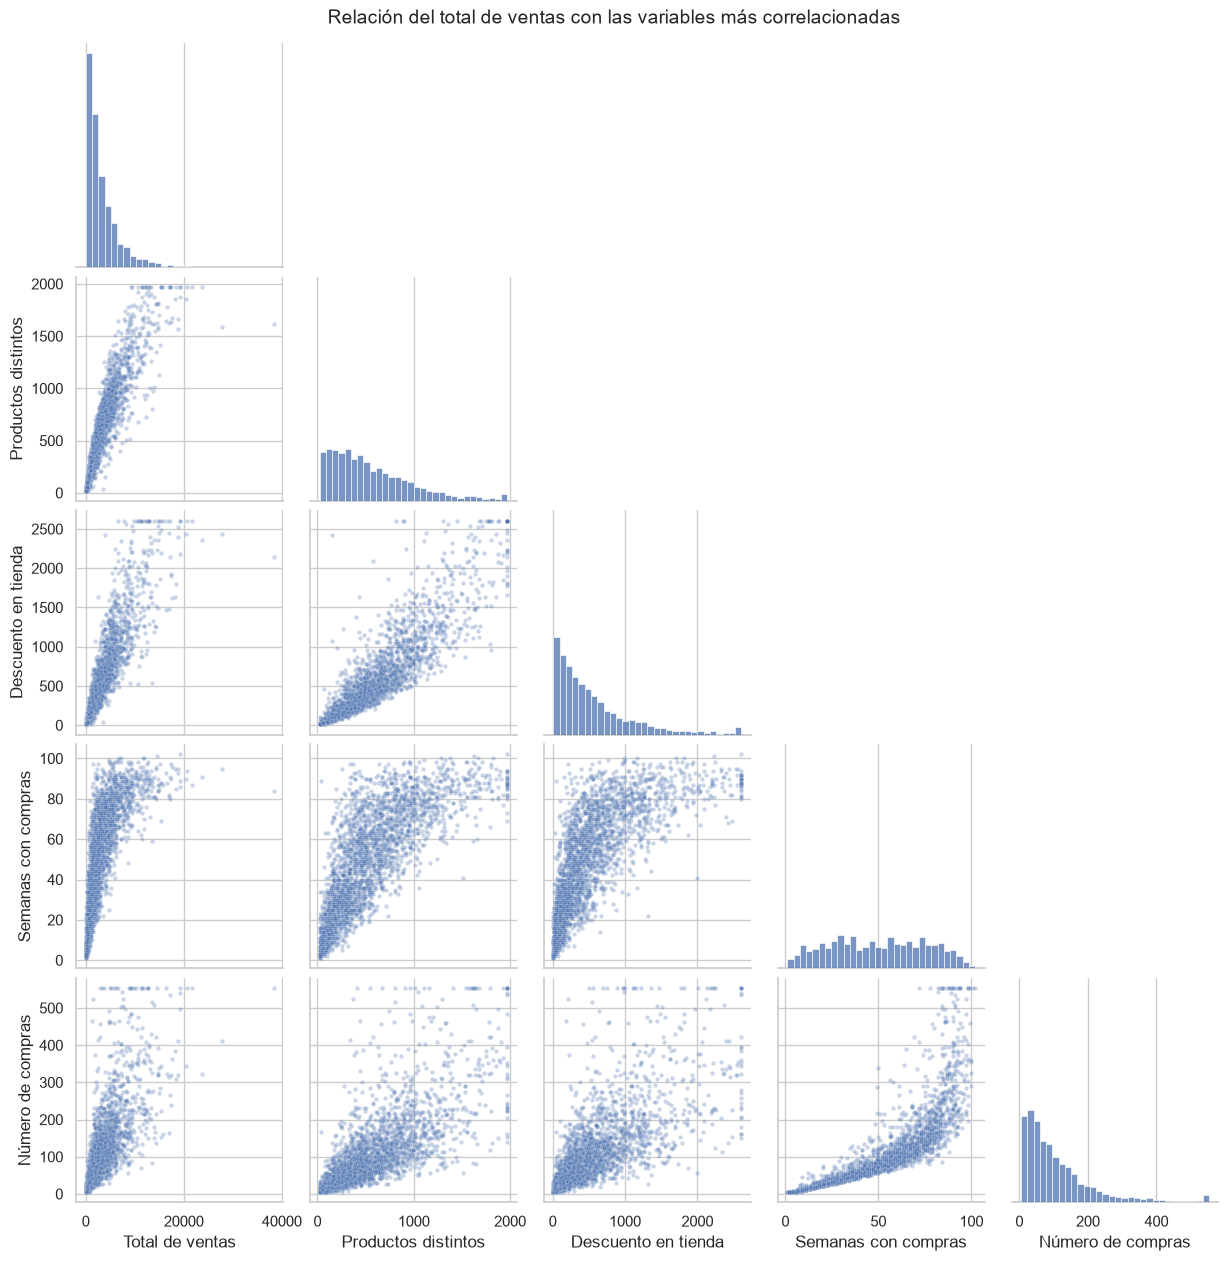

In [44]:
grafico_pares = sns.pairplot(df_sin_escalar[["total_ventas", "productos_distintos", "descuento_tienda",
                             "semanas_activas", "cantidad_compras"]]
             .rename(columns=etiqueta_grafico),
             corner=True, plot_kws={"alpha": 0.3, "s": 10}, diag_kws={"bins": 30})
for ax in grafico_pares.diag_axes:
    ax.set_ylabel("Frecuencia")
plt.suptitle("Relación del total de ventas con las variables más correlacionadas", y=1.01, fontsize=14)
plt.show()

**Lo que muestran las correlaciones**

* Las ventas se relacionan con los productos distintos (≈ 0,89), el descuento en tienda (≈ 0,88), la cantidad de compras (0,74) y las semanas activas (0,72). En este periodo, los hogares que gastan más también suelen comprar con más frecuencia y variedad. Estas relaciones no prueban causalidad.
* El ticket promedio tiene una relación moderada con las ventas y débil con la cantidad de compras. Hay que recordar que se calcula dividiendo las ventas entre las compras, por lo que contiene información directa del objetivo.
* Varias explicativas están correlacionadas entre sí, con valores absolutos superiores a 0,7. Es el caso de productos distintos, descuento en tienda, semanas activas y compras. Esta multicolinealidad debe revisarse antes de interpretar coeficientes de una regresión lineal.
* `tiene_demografia` se correlaciona 0,49 con las ventas. En esta muestra, los hogares con información demográfica tienen mayor gasto.
* Edad, ingreso y tamaño del hogar tienen correlaciones de aproximadamente 0,43–0,51 con las ventas y de 0,84–0,91 con el indicador de demografía. Parte de esa relación se debe al código 0 asignado a los desconocidos. La celda siguiente repite la comparación solo con los 801 hogares que tienen demografía: el ingreso presenta una asociación positiva débil y la edad una relación cercana a cero.
* El primer día de compra tiene una correlación cercana a cero con las ventas (≈ −0,03).

`cantidad_articulos` no forma parte de esta comparación, porque ya se retiró del conjunto procesado.

In [45]:
con_demografia = df_sin_escalar[df_sin_escalar["tiene_demografia"] == 1]
(con_demografia[["rango_ingreso", "tamano_hogar", "cantidad_hijos", "rango_edad", "total_ventas"]]
 .corr()["total_ventas"].drop("total_ventas").sort_values(ascending=False)
 .to_frame("r con total_ventas (solo 801 hogares con demografía)"))

,r con total_ventas (solo 801 hogares con demografía)
rango_ingreso,0.26
tamano_hogar,0.14
cantidad_hijos,0.14
rango_edad,-0.06


## 12. Variable dependiente y modelo candidato

La variable que se propone explicar es `total_ventas`: el gasto observado de cada hogar durante el periodo del conjunto de datos. Es un monto continuo en dólares, por lo que corresponde a un problema de regresión.

### Modelo propuesto

La regresión lineal múltiple es un candidato inicial. Permite estudiar la asociación del gasto con varias características de compra y ofrece coeficientes que se pueden interpretar. Las relaciones observadas con la frecuencia, la variedad y las semanas de actividad justifican evaluarla. Antes de interpretar sus coeficientes habría que revisar la multicolinealidad y la selección de variables. Una versión regularizada, como Ridge, podría compararse en esa etapa.

Random Forest Regressor queda como otra opción si se quieren estudiar relaciones no lineales o interacciones. Este laboratorio propone los candidatos; no los entrena ni presenta métricas de rendimiento.

### Qué habría que cuidar al entrenar

* Separar entrenamiento y prueba antes de calcular percentiles, agrupar categorías o escalar. Un `Pipeline` permite ajustar esos pasos con el entrenamiento; en validación cruzada, el ajuste debe repetirse dentro de cada partición.
* Excluir el identificador y evitar que el objetivo entre como predictor. También habría que excluir `ticket_promedio`, porque se obtiene de las propias ventas. La cantidad con unidades mixtas ya se retiró.
* Definir cuándo estaría disponible cada predictor. Las métricas actuales resumen el mismo periodo que las ventas y sirven para analizar el gasto observado. Para pronosticar gasto futuro se necesitarían características de un periodo anterior, ventas de uno posterior y una validación que respete ese orden.

La correlación ayuda a justificar el candidato, pero no sustituye una evaluación del modelo.

## 13. Guardado de los datos procesados

El resultado se guarda en `data_process.csv`: 2.500 filas y 31 columnas, sin nulos. Incluye los nombres en español, la imputación, el tratamiento de extremos, la conversión de tipos, la codificación de categorías y la estandarización de 14 variables.

La columna de cantidad con unidades mixtas queda únicamente en los datos originales. El CSV procesado recoge el EDA; para evaluar un modelo habría que volver a ajustar las transformaciones con el conjunto de entrenamiento.

In [46]:
df.to_csv("data_process.csv", index=False, encoding="utf-8")

verificacion = pd.read_csv("data_process.csv")
print(f"Archivo guardado: data_process.csv -> {verificacion.shape[0]:,} filas x {verificacion.shape[1]} columnas")
print(f"Nulos en el archivo guardado: {verificacion.isna().sum().sum()}")
verificacion.head()

Archivo guardado: data_process.csv -> 2,500 filas x 31 columnas
Nulos en el archivo guardado: 0


,id_hogar,rango_edad,rango_ingreso,tamano_hogar,cantidad_hijos,total_ventas,cantidad_compras,ticket_promedio,productos_distintos,tiendas_distintas,semanas_activas,primer_dia_compra,ultimo_dia_compra,descuento_tienda,descuento_cupon,cupones_canjeados,tiene_demografia,estado_civil_Desconocido,estado_civil_Soltero,tipo_vivienda_Homeowner,tipo_vivienda_Probable Owner,tipo_vivienda_Probable Renter,tipo_vivienda_Renter,composicion_hogar_2 Adults Kids,composicion_hogar_2 Adults No Kids,composicion_hogar_Desconocido,composicion_hogar_Single Female,composicion_hogar_Single Male,departamento_principal_GROCERY,departamento_principal_KIOSK-GAS,departamento_principal_OTROS
0,1,2.74,0.98,1.06,-0.29,"4,330.16",-0.22,1.04,0.28,-1.02,0.72,-0.38,0.33,0.27,1.91,1.48,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0
1,2,-0.63,-0.59,-0.57,-0.29,"1,954.34",-0.62,0.66,-0.03,-0.13,-0.57,0.95,-0.28,-0.41,-0.21,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
2,3,-0.63,-0.59,-0.57,-0.29,"2,653.21",-0.60,1.37,-0.10,-0.72,-0.49,1.20,0.28,0.23,1.34,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
3,4,-0.63,-0.59,-0.57,-0.29,"1,200.11",-0.77,0.47,-0.93,0.17,-0.92,0.97,-0.93,-0.82,-0.40,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
4,5,-0.63,-0.59,-0.57,-0.29,779.06,-0.67,-0.66,-0.85,-0.72,-0.88,0.49,0.28,-0.81,-0.47,-0.31,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0


## Resumen

El análisis parte de 2.500 hogares y conserva todas las filas. Los principales problemas son la falta de datos demográficos, los canjes sin registro y una cantidad que combina unidades distintas. Se tratan los nulos según su significado, se retira esa cantidad y se acotan siete métricas entre los percentiles 1 y 99.

Tras convertir categorías y estandarizar 14 variables, el resultado tiene 31 columnas y ningún nulo. Las ventas se asocian sobre todo con la variedad de productos, la frecuencia de compra y las semanas de actividad. A partir de esas relaciones se propone una regresión lineal múltiple y se deja Random Forest como alternativa para una evaluación posterior.